# Notebook 03 – Fine-tune transformer (roberta-base), chỉ đọc comment

**Mục tiêu:** có model "chính" đầu tiên và so nó với các baseline cổ điển của notebook 02.

**Cần biết trước khi đọc**
- Kernel: **Python (sqe-gpu)**, tức môi trường `C:\Users\ADMIN\venvs\sqe` có PyTorch chạy GPU. Kernel Python 3.14 thường chỉ có PyTorch CPU, nên train sẽ rất chậm.
- Code train nằm trong `src/sqe/train.py` (có chú thích tiếng Việt từng bước). Notebook này chỉ gọi hàm và giải thích kết quả.
- Kết quả train được lưu đệm: chạy lại notebook sẽ đọc từ `outputs/oof/` và `outputs/runs/`, mất vài giây thay vì train lại. Muốn train lại thì xoá file trong `outputs/runs/` hoặc gọi `force=True`.

**Nội dung**
1. Bảng mốc so sánh: random, majority, TF-IDF, làm cho **cả A và B** (notebook 02 mới làm B)
2. Transformer làm gì với một câu?
3. Train roberta-base theo 5 fold cho A và cho B
4. So sánh với TF-IDF, xem confusion matrix và learning curve
5. Kết luận

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sqe").exists())
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay

from sqe import classical
from sqe.data import TASKS, load_en
from sqe.metrics import fmt, fold_scores, paired_delta
from sqe.results import load_oof, log_result, save_oof

pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)
df = load_en()
print("Số mẫu:", len(df), "| số video:", df.video_id.nunique())
print("Thiết bị:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (sẽ rất chậm!)")

Số mẫu: 2989 | số video: 243
Thiết bị: NVIDIA RTX A2000 Laptop GPU


## 1. Bảng mốc so sánh (baseline cổ điển)

Cấu hình giống hệt notebook 02 (`src/sqe/classical.py`), chạy cho cả hai subtask và hai kiểu input:
- **random**: đoán bừa đều các lớp → mức "không học gì".
- **majority**: luôn đoán lớp đông nhất → macro-F1 rất thấp, vì các lớp còn lại có F1 = 0.
- **TF-IDF + LR**: đếm từ / cụm ký tự rồi phân loại tuyến tính → baseline "thật" cần vượt qua.

File OOF được lưu với tên mới (`tfidf_comment_*.csv`...) nên không đè lên file OOF của notebook 02.

In [2]:
baseline_rows = []
for subtask in ["A", "B"]:
    labels = TASKS[subtask][1]
    for model_name, input_name, texts in [
        ("random", "comment", df["yt_comment"]),
        ("majority", "comment", df["yt_comment"]),
        ("tfidf_lr", "comment", df["yt_comment"]),
        ("tfidf_lr", "comment_title", df["yt_comment"] + "\n" + df["yt_title"]),
    ]:
        oof = classical.run_cv(df, model_name, texts.tolist(), subtask)
        name = f"{model_name.replace('_lr', '')}_{input_name}"
        save_oof(oof, name, subtask)
        sc = fold_scores(oof, labels)
        log_result("03", model_name, input_name, subtask, sc, note="baseline cổ điển (cấu hình notebook 02)")
        baseline_rows.append({"subtask": subtask, "model": model_name, "input": input_name,
                              "macro_f1": sc.macro_f1.mean(), "std": sc.macro_f1.std(ddof=0),
                              **{c: sc[c].mean() for c in sc.columns if c.startswith("f1_")}})

baseline = pd.DataFrame(baseline_rows)
baseline

,subtask,model,input,macro_f1,std,f1_no,f1_yes,f1_yes_implicit,f1_yes_explicit
0,A,random,comment,0.4998,1.3186e-02,0.5286,0.4709,NaN,NaN
1,A,majority,comment,0.3575,2.5410e-04,0.7150,0.0000,NaN,NaN
2,A,tfidf_lr,comment,0.7002,2.0919e-02,0.7333,0.6671,NaN,NaN
3,A,tfidf_lr,comment_title,0.6775,2.3404e-02,0.7124,0.6426,NaN,NaN
4,B,random,comment,0.3323,5.0220e-03,0.3961,NaN,0.2960,0.3047
5,B,majority,comment,0.2134,1.4778e-05,0.6401,NaN,0.0000,0.0000
6,B,tfidf_lr,comment,0.5249,1.3831e-02,0.6782,NaN,0.3857,0.5107
7,B,tfidf_lr,comment_title,0.4833,2.1621e-02,0.6705,NaN,0.3113,0.4682


**Kiểm tra chéo với notebook 02:** TF-IDF chỉ comment cho B ở đây phải ra đúng con số của notebook 02 (0,5249), vì cùng cấu hình và cùng fold.

In [3]:
nb02 = pd.read_csv(ROOT / "outputs/oof/tfidf_lr_comment_B.csv")
mine = load_oof("tfidf_comment", "B")
same = (nb02.sort_values("StereoQueerEval_id")["y_pred"].to_numpy()
        == mine.sort_values("StereoQueerEval_id")["y_pred"].to_numpy()).mean()
print(f"Tỉ lệ dự đoán trùng với notebook 02: {same:.1%}")
print("Macro-F1 B (tính lại):", fmt(fold_scores(mine, TASKS["B"][1])))

Tỉ lệ dự đoán trùng với notebook 02: 100.0%
Macro-F1 B (tính lại): 0.5249 ± 0.0138


**Đọc bảng:**
- Thêm title vào TF-IDF làm **giảm** điểm ở B (notebook 02 đã thấy). Lý do có thể là: mọi comment cùng một video có chung title, nên các từ trong title trở thành "mã nhận diện video". Model học "video X → nhãn Y", mà test lại là video mới nên mẹo này không dùng được.
- Đây là lý do roadmap đặt câu hỏi: transformer có tận dụng context **tốt hơn** TF-IDF không? Notebook 04 sẽ trả lời.

## 2. Transformer làm gì với một câu?

1. **Tokenizer** cắt câu thành các mảnh từ (subword), thêm `<s>` ở đầu và `</s>` ở cuối.
2. **Encoder** (12 lớp self-attention của roberta-base, 125 triệu tham số, đã học trước trên rất nhiều văn bản tiếng Anh) biến mỗi token thành một vector 768 chiều. Mỗi vector "biết" ngữ cảnh của cả câu.
3. Lấy vector của `<s>` làm đại diện cho cả câu, rồi đưa qua một **head** nhỏ (dense → tanh → linear) để ra điểm cho từng lớp.
4. **Fine-tune:** cập nhật cả encoder lẫn head để giảm cross-entropy loss trên tập train. Learning rate nhỏ (2e-5) để không phá kiến thức đã học trước.

Ví dụ tokenizer với một comment, và với cặp câu (comment, title) mà notebook 04 sẽ dùng:

In [4]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("roberta-base")
ex = df.iloc[1]
print("Comment:", ex.yt_comment)
print("Tokens :", tok.convert_ids_to_tokens(tok(ex.yt_comment)["input_ids"]))
print("\nCặp câu (comment, title):")
print(tok.convert_ids_to_tokens(tok(ex.yt_comment, ex.yt_title)["input_ids"]))
lens = [len(x) for x in tok(df["yt_comment"].tolist())["input_ids"]]
print(f"\nĐộ dài comment (token): trung vị {np.median(lens):.0f}, 95% ≤ {np.percentile(lens, 95):.0f}, "
      f"> 128 token: {np.mean(np.array(lens) > 128):.1%}")

C:\Users\ADMIN\venvs\sqe\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (550 > 512). Running this sequence through the model will result in indexing errors


Comment: Rep Mace: Keep on being dedicated to truth and NOT politically correct propaganda! Thank you for your leadership.
Tokens : ['<s>', 'Rep', 'ĠMace', ':', 'ĠKeep', 'Ġon', 'Ġbeing', 'Ġdedicated', 'Ġto', 'Ġtruth', 'Ġand', 'ĠNOT', 'Ġpolitically', 'Ġcorrect', 'Ġpropaganda', '!', 'ĠThank', 'Ġyou', 'Ġfor', 'Ġyour', 'Ġleadership', '.', '</s>']

Cặp câu (comment, title):
['<s>', 'Rep', 'ĠMace', ':', 'ĠKeep', 'Ġon', 'Ġbeing', 'Ġdedicated', 'Ġto', 'Ġtruth', 'Ġand', 'ĠNOT', 'Ġpolitically', 'Ġcorrect', 'Ġpropaganda', '!', 'ĠThank', 'Ġyou', 'Ġfor', 'Ġyour', 'Ġleadership', '.', '</s>', '</s>', 'GOP', 'ĠCongress', 'woman', 'Ġuses', 'Ġanti', '-', 'trans', 'Ġslur', 'Ġin', 'ĠHouse', 'Ġhearing', '</s>']

Độ dài comment (token): trung vị 25, 95% ≤ 123, > 128 token: 4.5%


## 3. Train roberta-base theo 5 fold

Cấu hình (chọn trước, **không** dò trên fold validation):

| Tham số | Giá trị | Ý nghĩa |
|---|---|---|
| model | `roberta-base` | encoder tiếng Anh phổ biến |
| input | chỉ comment | context để dành cho notebook 04 |
| max_length | 128 | 95% comment ngắn hơn mức này |
| lr | 2e-5 | learning rate quen dùng khi fine-tune BERT/RoBERTa |
| epochs | 4 | cố định, lấy model ở epoch cuối |
| batch | 16 | |
| warmup | 10% | lr tăng dần ở đầu để train ổn định |

Mỗi fold in ra loss và macro-F1 trên fold validation sau từng epoch. Con số validation chỉ để **theo dõi**; dự đoán OOF luôn lấy ở epoch cuối.

In [5]:
from sqe.train import load_history, run_cv

CFG = dict(model="roberta-base", input="comment", max_length=128)
oof_A = run_cv(df, "roberta_comment", CFG, tasks=("A",))["A"]

  fold 0: train 2390 | valid 599


    epoch 1: loss 0.6606 | val macro-F1 A 0.6874


    epoch 2: loss 0.5156 | val macro-F1 A 0.7408


    epoch 3: loss 0.3554 | val macro-F1 A 0.7344


    epoch 4: loss 0.2329 | val macro-F1 A 0.7314


...

    epoch 1: loss 0.6425 | val macro-F1 A 0.6947


    epoch 2: loss 0.5129 | val macro-F1 A 0.6753


    epoch 3: loss 0.3552 | val macro-F1 A 0.7162


    epoch 4: loss 0.2316 | val macro-F1 A 0.7172


  xong roberta_comment trong 8.5 phút


In [6]:
oof_B = run_cv(df, "roberta_comment", CFG, tasks=("B",))["B"]

  fold 0: train 2390 | valid 599


    epoch 1: loss 1.0392 | val macro-F1 B 0.3879


    epoch 2: loss 0.8331 | val macro-F1 B 0.5490


    epoch 3: loss 0.6429 | val macro-F1 B 0.6070


    epoch 4: loss 0.4923 | val macro-F1 B 0.6171


...

    epoch 1: loss 1.0293 | val macro-F1 B 0.4494


    epoch 2: loss 0.8288 | val macro-F1 B 0.5756


    epoch 3: loss 0.6161 | val macro-F1 B 0.5545


    epoch 4: loss 0.4530 | val macro-F1 B 0.5714


  xong roberta_comment trong 8.7 phút


In [7]:
for subtask, oof in [("A", oof_A), ("B", oof_B)]:
    sc = fold_scores(oof, TASKS[subtask][1])
    log_result("03", "roberta-base", "comment", subtask, sc, note="lr2e-5 ep4 bs16 len128")
    print(f"roberta-base | {subtask}: {fmt(sc)}")

roberta-base | A: 0.7274 ± 0.0098
roberta-base | B: 0.5856 ± 0.0179


## 4. So sánh với TF-IDF

In [8]:
rows = []
for subtask in ["A", "B"]:
    labels = TASKS[subtask][1]
    for name, label in [("majority_comment", "majority"), ("tfidf_comment", "TF-IDF + LR"),
                        ("roberta_comment", "roberta-base")]:
        sc = fold_scores(load_oof(name, subtask), labels)
        rows.append({"subtask": subtask, "model": label, "macro_f1": sc.macro_f1.mean(),
                     "std": sc.macro_f1.std(ddof=0),
                     **{c: sc[c].mean() for c in sc.columns if c.startswith("f1_")}})
compare = pd.DataFrame(rows)
compare

,subtask,model,macro_f1,std,f1_no,f1_yes,f1_yes_implicit,f1_yes_explicit
0,A,majority,0.3575,2.5410e-04,0.7150,0.0000,NaN,NaN
1,A,TF-IDF + LR,0.7002,2.0919e-02,0.7333,0.6671,NaN,NaN
2,A,roberta-base,0.7274,9.7725e-03,0.7590,0.6958,NaN,NaN
3,B,majority,0.2134,1.4778e-05,0.6401,NaN,0.0000,0.0000
4,B,TF-IDF + LR,0.5249,1.3831e-02,0.6782,NaN,0.3857,0.5107
5,B,roberta-base,0.5856,1.7904e-02,0.7311,NaN,0.4332,0.5925


**So sánh cặp theo fold.** Hai model chạy trên cùng 5 fold, nên xem chênh lệch *từng fold* đáng tin hơn so hai con số trung bình. Thắng 5/5 fold là chắc chắn hơn nhiều so với thắng 3/5.

In [9]:
for subtask in ["A", "B"]:
    labels = TASKS[subtask][1]
    d = paired_delta(fold_scores(oof_A if subtask == "A" else oof_B, labels),
                     fold_scores(load_oof("tfidf_comment", subtask), labels))
    print(f"{subtask}: roberta − TF-IDF = {d['delta_mean']:+.4f} (±{d['delta_std']:.4f}), "
          f"thắng {d['wins']}/{d['n_folds']} fold")

A: roberta − TF-IDF = +0.0272 (±0.0190), thắng 5/5 fold
B: roberta − TF-IDF = +0.0607 (±0.0207), thắng 5/5 fold


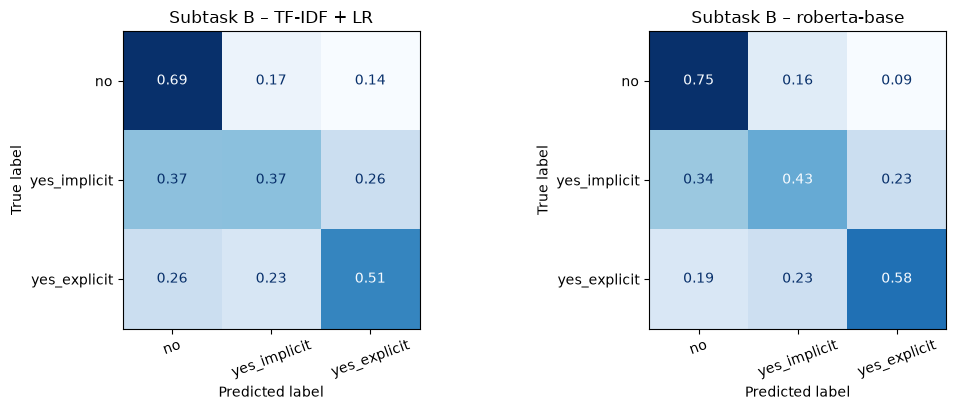

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, title) in zip(axes, [("tfidf_comment", "TF-IDF + LR"), ("roberta_comment", "roberta-base")]):
    o = load_oof(name, "B")
    ConfusionMatrixDisplay.from_predictions(o.y_true, o.y_pred, labels=TASKS["B"][1], normalize="true",
                                            values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Subtask B – {title}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Mỗi hàng của confusion matrix là **nhãn thật**, đã chuẩn hoá về tổng = 1, nên đường chéo chính là recall của từng lớp. Ô (implicit → explicit) và ô (explicit → implicit) cho thấy model nhầm giữa hai kiểu hate speech nhiều đến mức nào.

### Learning curve: 4 epoch có hợp lý không?

Đường dưới đây là macro-F1 trên fold validation sau từng epoch, lấy trung bình 5 fold. Nó chỉ để **chẩn đoán**: nếu đường còn đi lên ở epoch 4 thì có thể train thêm; nếu đã đi xuống thì đang overfit. Không dùng nó để chọn epoch cho từng fold, vì như vậy là nhìn trộm đáp án.

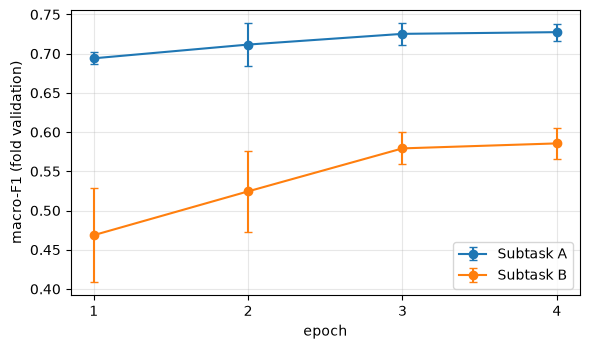

Thời gian train 5 fold (A): 8.5 phút trên cuda


In [11]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for subtask in ["A", "B"]:
    h, _ = load_history("roberta_comment", (subtask,))
    curve = h.groupby("epoch")[f"val_f1_{subtask}"].agg(["mean", "std"])
    ax.errorbar(curve.index, curve["mean"], yerr=curve["std"], marker="o", capsize=3, label=f"Subtask {subtask}")
ax.set_xlabel("epoch")
ax.set_ylabel("macro-F1 (fold validation)")
ax.set_xticks(range(1, 5))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
h_A, meta = load_history("roberta_comment", ("A",))
print(f"Thời gian train 5 fold (A): {meta['minutes']:.1f} phút trên {meta['device']}")

## 5. Kết luận

**1. roberta-base vượt TF-IDF rõ ràng ở cả hai subtask, thắng 5/5 fold.**

| Subtask | majority | TF-IDF + LR | roberta-base | Δ (roberta − TF-IDF) |
|---|---|---|---|---|
| A | 0,357 | 0,700 ± 0,021 | **0,727 ± 0,010** | +0,027, thắng 5/5 fold |
| B | 0,213 | 0,525 ± 0,014 | **0,586 ± 0,018** | +0,061, thắng 5/5 fold |

B được lợi nhiều hơn A: phân biệt hate speech cần hiểu nghĩa, còn đếm từ thì không đủ.

**2. Ở B, lỗi lớn nhất không phải "nhầm implicit ↔ explicit" mà là bỏ sót implicit.** Xem confusion matrix (theo hàng):
- `yes_implicit`: chỉ 43% đoán đúng; **34% bị đoán thành `no`** và 23% bị đoán thành `explicit`.
- `yes_explicit`: 58% đúng, 23% thành implicit, 19% thành no.
- F1 từng lớp: no 0,73 · implicit 0,43 · explicit 0,59. Lớp implicit kéo macro-F1 xuống nhiều nhất.

Nghĩa là: chỉ đọc comment thì nhiều câu hate *ngầm* trông giống hệt câu bình thường. Điều này khớp với EDA (77% comment implicit không nhắc tới nhóm bị nhắm) và là lý do chính để thử **đưa context video vào ở notebook 04**.

**3. Learning curve** (macro-F1 trên fold validation, trung bình 5 fold, epoch 1 → 4):
- A: 0,694 → 0,712 → 0,725 → 0,727. Đã gần như bão hoà, nên 4 epoch là đủ.
- B: 0,469 → 0,524 → 0,579 → 0,586. Vẫn còn tăng nhẹ ở epoch 4.

Có thể thử train B lâu hơn (5–6 epoch), nhưng phải coi đó là **một thí nghiệm riêng, khai báo trước** (chạy đủ 5 fold rồi so cặp), chứ không được chọn epoch dựa trên đường cong này.

**4. Chi phí:** khoảng 8,5 phút cho 5 fold × 4 epoch trên GPU laptop 4 GB (RTX A2000, bf16).

**Việc tiếp theo:** notebook 04, thử đưa title/description vào (C1–C3) và đổi encoder.
